# 05-1. Supervisor 패턴 — LLM 기반 동적 라우팅
**학습 목표:** 02·03번의 고정 `add_edge` 대신 `add_conditional_edges`를 사용해, Supervisor Agent가 사용자 질문을 보고 다음에 어떤 전문 Agent를 호출할지 **실행 중에 직접 결정**하게 만든다. `.env`의 `OPENAI_API_KEY`로 실제 LLM을 호출하므로 실행마다 비용이 발생한다.


## 1. 핵심 개념 — 고정 파이프라인과 동적 라우팅의 차이
02번(Sequential)과 03번(Hybrid)은 어떤 Agent가 다음에 실행될지를 `add_edge`로 **코드에 미리 고정**해 두었다. 이 Notebook은 그 결정을 Supervisor Node가 실행 중에 내리게 한다. Supervisor는 LLM에게 "이 질문은 세 전문 Agent 중 누가 맡아야 하는가"만 판단하게 하고, 그 결과를 `add_conditional_edges`의 분기 기준으로 사용한다.

```mermaid
flowchart TD
  S[START] --> SV[Supervisor: LLM이 라벨 판단]
  SV -->|fit_agent| F[Fit Agent]
  SV -->|interview_agent| I[Interview Agent]
  SV -->|strategy_agent| T[Strategy Agent]
  F --> E[END]
  I --> E
  T --> E
```

세 전문 Agent는 서로 배타적으로 하나만 실행되므로(동시에 여러 개가 실행되는 03번의 Fan-out과 다름), 모두 같은 State Key(`agent_response`)에 써도 충돌하지 않는다.


## 2. Import와 LLM 설정
`common.ai_model.get_llm_model()`은 `.env`의 `OPENAI_API_KEY`로 `ChatOpenAI`를 초기화한다. 같은 클라이언트를 Supervisor의 라우팅 판단과 전문 Agent의 답변 생성에 모두 사용한다.


In [1]:
from typing import TypedDict

from langgraph.graph import START, END, StateGraph

from common.ai_model import get_llm_model

llm = get_llm_model()

print(llm.model_name)


Qwen/Qwen3-4B-FP8


## 3. 샘플 데이터
04번 미션과 같은 형태의 채용공고·이력서를 간단히 줄여서 재사용한다. 이 Notebook의 초점은 라우팅 로직이지 역량 비교 자체가 아니므로, 전문 Agent는 이 데이터를 참고 자료로만 사용한다.


In [2]:
job_posting = {
    "title": "백엔드 개발자",
    "required_skills": ["Python", "SQL", "REST API"],
    "preferred_skills": ["LangGraph", "Docker"],
    "required_experience": "실무 2년 이상",
}

candidate_resume = {
    "name": "홍길동",
    "skills": ["Python", "LangGraph", "Docker"],
    "experience": "스타트업에서 1년간 백엔드 인턴 경험",
}

print(job_posting["title"], "/", candidate_resume["name"])


백엔드 개발자 / 홍길동


## 4. State 설계
`route`는 Supervisor가 쓰고 `add_conditional_edges`가 읽는 Key다. `ROUTES`는 Supervisor가 고를 수 있는 라벨과 Graph Node 이름을 동시에 정의한다.


In [3]:
class SupportState(TypedDict, total=False):
    user_query: str
    job_posting: dict
    candidate_resume: dict
    route: str
    agent_response: str


# 라벨 이름을 그대로 Graph의 Node 이름으로도 사용한다.
ROUTES = ("fit_agent", "interview_agent", "strategy_agent")


## 5. Supervisor — 라우팅 판단
Supervisor는 질문에 답하지 않는다. 세 라벨 중 하나만 고른다. 이 판단 결과가 `add_conditional_edges`의 분기 기준이 된다.


In [4]:
import re


def strip_think(text: str) -> str:
    """Qwen3 같은 추론 모델이 답변 앞에 붙이는 <think>...</think> 블록을 제거한다."""
    return re.sub(r"<think>.*?</think>", "", text, flags=re.DOTALL).strip()


def supervisor(state: SupportState) -> dict:
    """사용자 질문 하나만 보고 세 전문 Agent 중 누가 답해야 할지 모델이 직접 고르게 한다."""
    prompt = (
        "아래 질문에 가장 적합한 담당자를 정확히 하나만, 다른 말 없이 라벨로만 답하라.\n"
        "fit_agent: 지원자 역량·자격이 채용공고 요건에 맞는지에 대한 질문\n"
        "interview_agent: 면접 준비, 예상 질문에 대한 질문\n"
        "strategy_agent: 지원 전략, 취업 방향에 대한 질문\n"
        f"라벨은 반드시 {ROUTES} 중 하나.\n질문: {state['user_query']}"
    )
    label = strip_think(llm.invoke(prompt).content)
    # 모델이 지시를 어기고 다른 텍스트를 반환해도 Graph가 멈추지 않도록 기본 라벨을 둔다.
    return {"route": label if label in ROUTES else "strategy_agent"}


def route_after_supervisor(state: SupportState) -> str:
    """add_conditional_edges가 호출하는 판단 함수. supervisor가 쓴 State Key를 그대로 읽어 다음 Node 이름을 고른다."""
    return state['route']


## 6. 전문 Agent 세 개
셋 중 하나만 실행되므로 서로 다른 Key를 나눠 쓸 필요가 없다. 모두 같은 `agent_response` Key에 쓴다.


In [5]:
def fit_agent(state: SupportState) -> dict:
    """역량·자격 비교 질문에 답한다."""
    prompt = (
        "당신은 역량 비교 담당자다. 채용공고 요건과 지원자 보유 역량을 비교해 질문에 답하라. "
        "공고·이력서에 없는 내용은 추측하지 마라.\n"
        f"채용공고: {state['job_posting']}\n이력서: {state['candidate_resume']}\n"
        f"질문: {state['user_query']}"
    )
    return {"agent_response": strip_think(llm.invoke(prompt).content)}


def interview_agent(state: SupportState) -> dict:
    """면접 준비 질문에 답한다."""
    prompt = (
        "당신은 면접 코치다. 채용공고와 이력서를 참고해 예상 질문과 답변 방향을 제시하라.\n"
        f"채용공고: {state['job_posting']}\n이력서: {state['candidate_resume']}\n"
        f"질문: {state['user_query']}"
    )
    return {"agent_response": strip_think(llm.invoke(prompt).content)}


def strategy_agent(state: SupportState) -> dict:
    """지원 전략 질문에 답한다."""
    prompt = (
        "당신은 취업 전략 어드바이저다. 지원자의 강점과 공고 요건을 고려해 지원 전략을 제시하라.\n"
        f"채용공고: {state['job_posting']}\n이력서: {state['candidate_resume']}\n"
        f"질문: {state['user_query']}"
    )
    return {"agent_response": strip_think(llm.invoke(prompt).content)}


## 7. Graph 구성 — `add_conditional_edges`
`add_edge`는 다음 Node를 하나로 고정하지만, `add_conditional_edges`는 판단 함수의 반환값에 따라 여러 Node 중 하나로 보낸다. 세 번째 인자(dict)는 "판단 함수가 반환한 값" → "실제 Node 이름"의 매핑이다.


In [6]:
builder = StateGraph(SupportState)
builder.add_node("supervisor", supervisor)
builder.add_node("fit_agent", fit_agent)
builder.add_node("interview_agent", interview_agent)
builder.add_node("strategy_agent", strategy_agent)

builder.add_edge(START, "supervisor")
# 02·03번과 다른 지점: 다음 Node가 고정되어 있지 않고 route_after_supervisor의 반환값으로 정해진다.
builder.add_conditional_edges("supervisor", route_after_supervisor, {r: r for r in ROUTES})
builder.add_edge("fit_agent", END)
builder.add_edge("interview_agent", END)
builder.add_edge("strategy_agent", END)
graph = builder.compile()


## 8. Graph 시각화
Supervisor에서 세 갈래로 나가는 점선 화살표가 조건부 Edge다.


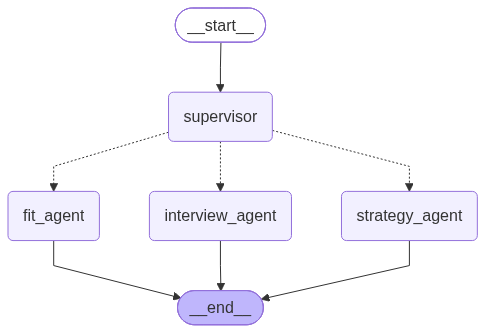

In [7]:
from IPython.display import Image, display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as exc:
    # 시각화 서비스가 없어도 Graph의 실행은 계속된다.
    print("PNG 시각화 불가:", type(exc).__name__)
    print(graph.get_graph().draw_mermaid())


## 9. 실행과 라우팅 검증
서로 다른 유형의 질문 세 개를 넣어, Supervisor가 매번 다른 전문 Agent로 보내는지 확인한다. `temperature=0`이라 분류가 대체로 안정적이지만, 100% 결정적이라는 보장은 없다 — 라우팅이 자주 틀린다면 Supervisor 프롬프트의 라벨 설명을 더 구체화해야 한다. 질문마다 Supervisor·전문 Agent가 각각 LLM을 호출하므로 호출당 2회의 API 비용이 발생한다.


In [8]:
test_cases = [
    ("SQL 역량이 부족한데 이 공고에 지원할 수 있을까요?", "fit_agent"),
    ("이 공고 면접에서 어떤 질문이 나올까요?", "interview_agent"),
    ("이 공고에 지원할 때 어떤 전략으로 접근해야 하나요?", "strategy_agent"),
]

results = []
for query, expected_route in test_cases:
    state = {"user_query": query, "job_posting": job_posting, "candidate_resume": candidate_resume}
    result = graph.invoke(state)
    results.append(result)
    print(f"질문: {query}")
    print(f"라우팅: {result['route']} (기대: {expected_route})")
    print(result["agent_response"][:200], "...\n")
    assert result["route"] == expected_route


질문: SQL 역량이 부족한데 이 공고에 지원할 수 있을까요?
라우팅: fit_agent (기대: fit_agent)
**답변:**  
아니요, SQL 역량이 부족하여 이 공고에 지원할 수 없습니다. 채용공고에서 **필수 역량**으로 명시된 **SQL**을 보유하고 있지 않기 때문입니다. 이력서에 SQL 관련 경력이나 기술이 언급되지 않았으며, 공고의 실무 2년 이상 경험 요건도 충족하지 못하는 상황입니다. 따라서 해당 채용공고에 지원할 자격이 없습니다. ...

질문: 이 공고 면접에서 어떤 질문이 나올까요?
라우팅: interview_agent (기대: interview_agent)
### 면접 예상 질문 및 답변 방향

#### **1. 기술적 역량 관련 질문**
**질문 1:**  
"Python을 사용한 실제 프로젝트에서 어떤 작업을 하셨나요? 구체적인 예를 들어주세요."  
**답변 방향:**  
- **Python 활용 사례**를 구체적으로 설명 (예: API 개발, 데이터 처리, 스크립트 작성).  
- **문제 해결** 과 ...

질문: 이 공고에 지원할 때 어떤 전략으로 접근해야 하나요?
라우팅: strategy_agent (기대: strategy_agent)
이 공고에 지원하기 위한 전략은 **강점 강조 + 부족한 요소에 대한 적극적 대응**을 중심으로 구성해야 합니다. 아래에 구체적인 접근 방식을 제시합니다:

---

### **1. 강점 강조: 핵심 기술과 경험을 중심으로**
- **Python, LangGraph, Docker**  
  - 이력서에 명시된 기술은 **필수 요건(Python)과 선호 요건 ...



## 10. 핵심 개념 정리와 수강생 미션
`add_conditional_edges`는 "다음 Node가 무엇인가"라는 질문 자체를 실행 중 판단으로 바꾼다. Supervisor는 텍스트를 생성하지 않고 라벨만 고르도록 역할을 좁혀야 라우팅이 안정적이다.

**미션:** 네 번째 라우트(예: 이력서 전반 피드백을 주는 `feedback_agent`)를 추가하라. State에 새 분기가 필요 없는지 확인하고, `ROUTES`·Supervisor 프롬프트·`add_conditional_edges` 매핑·새 Node와 `add_edge(새_Node, END)`까지 빠짐없이 수정하라.
